> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D22_LLM_API연동_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **인용 블록(왼쪽 세로줄)으로 된 🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 단계별로 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 · 보안 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: D21에서 만든 음성 루프의 **두뇌를 상용 API로 바꾸고, 기억(이력)을 붙이는 날**입니다. 핵심 메시지는 **"세 API는 같은 다섯 가지를 받는다 → 하나의 함수로 감싸고 같은 조건에서 잰다 → 음성용 답은 프롬프트 + 자동 점검으로 만든다 → LLM은 기억이 없으니 이력을 설계한다"** 입니다. 칠판에 쓰는 식은 **요금 = 입력 × 단가 + 출력 × 단가**, **보낼 메시지 = 최근 N턴 × 2 + 1** 두 개입니다.
>
> > 🍎 **하루를 꿰는 비유: 세 나라 택배 회사 + 회의록.** 송장 칸 이름만 다른 택배(API)를 변환기 하나로 보내고, 매번 회의록(이력)을 챙겨 보낸다.
>
> > ⚠️ **보안 원칙 (먼저 공지)**: API 키는 Colab 보안 비밀에만. 화면 공유 · 캡처 · 노션 제출에 키가 보이지 않게. 강사 키를 학생과 공유하지 마세요(필요하면 수업용 한도를 건 별도 키).
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치, Part 1 API 구조 · 키, Part 2 `ask()` | 1 · 2 · 3 | D22-1, D22-2, D22-3 | p.1 ~ 8 |
> | 1:00–1:50 | 2교시 | Part 3 TTFT · 속도 · 비용 비교, 생각 모드 | 4 · 5 | D22-4, D22-8 | p.9 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 4 음성 프롬프트 · 자동 점검, Part 5 대화 이력 | 6 · 7 · 8 | D22-5, D22-6, D22-7 | p.12 ~ 16 |
> | 3:00–3:50 | 4교시 | Part 6 음성 루프 3턴 대화, Part 7 정리 · 과제 | 9 | D22-9 | p.17 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 3 `REPS = 1`
> 2. Part 4 질문을 4개로 (`LINT_QS[:4]`)
> 3. Part 5 전략 실험을 '최근 2턴'과 '최근 2턴 + 요약' 두 개만
>
> #### 수업 전 점검 (전날)
> - [ ] **모델 이름 · 가격 확인**: 노트북의 `MODELS` · `PRICES`는 2026년 10월 공개 자료 기준 예입니다. 각 회사 문서에서 당일 이름 · 가격을 확인해 고쳐 두세요(특히 Gemini 단가는 출처마다 다름).
> - [ ] 세 API 키로 처음부터 끝까지 한 번 실행(약 15 ~ 20분)하고 Part 2 · 3 · 4 · 5 · 6 표를 캡처. 키 없는 상태로도 한 번 실행해 local만으로 도는지 확인.
> - [ ] 학생 키 준비 안내: 무료 등급 키(분당 요청 제한 → 429 가능), 결제 키라면 **사용 한도(budget)** 설정 필수.
> - [ ] 키가 없는 학생은 local로 진행하고, 강사 화면으로 API 결과를 함께 봅니다(불이익 없음).
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day22/animation.html), [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html) 탭을 열어 둡니다.
> - [ ] 학생 안내문:
>
> ```
> D22 실습 노트북: (Colab 링크) → [파일] → [Drive에 사본 저장]
> 런타임 → T4 GPU
> API 키(선택): 왼쪽 열쇠 메뉴 → ANTHROPIC_API_KEY / OPENAI_API_KEY / GEMINI_API_KEY → 노트북 액세스 켜기
> 키를 코드 · 노션 · 깃허브에 붙이지 않기
> 워크시트: https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html
> ```
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 1 키 셀 | 키를 넣었는데 '키 없음' | 보안 비밀의 '노트북 액세스' 스위치 · 이름 철자 확인 |
> | Part 2 | `NotFoundError` / `404 model` | 모델 이름이 바뀜 → 문서에서 현재 이름 확인해 `MODELS` 수정 |
> | Part 2 | `400 temperature` 류 오류 | 직접 temperature를 넣은 경우 → 빼기 (최신 API는 받지 않음) |
> | Part 2 | Gemini 첫 호출에 '추가 옵션이 거부됨' 안내 | 정상: 그 모델이 thinking_level을 지원하지 않아 자동으로 빼고 재시도 |
> | Part 3 | `429 RateLimit` | 무료 등급 제한 → `REPS = 1`, 잠시 후 다시 |
> | Part 3 | 출력 토큰은 많은데 답이 짧음 | 생각(reasoning) 토큰 → 모델 문서의 생각 정도 옵션 확인 |
> | Part 5 | Claude `messages: first message must use the user role` | 이력을 홀수로 자른 경우 → 빈칸 7이 2인지 확인 |

> ## 🎤 강사 스크립트 · 오늘의 비유 사전 (먼저 읽어 두기)
>
> | 개념 | 🍎 한 문장 비유 |
> |---|---|
> | 세 API | 송장 칸 이름만 다른 **세 나라 택배 회사** |
> | `ask()` | **송장 변환기** |
> | API 키 | **집 열쇠** — 복사본이 돌면 바꿔야 함 |
> | 토큰 요금 | **글자 수로 매기는 전보** 요금 |
> | TTFT | 전화 걸고 **'여보세요'까지** |
> | 생각 모드 | 대답 전에 **속으로 길게 고민** |
> | 음성 프롬프트 | **라디오 원고** 쓰는 법 |
> | voice_lint | **방송 전 원고 검수** |
> | 대화 이력 | 매번 들고 가는 **회의록** |
> | 요약 | 지난 1년치 회의록의 **요약 한 장** |
> | 끼어들기 저장 | 회의록에는 **실제로 말한 것만** |

# D22. LLM API 연동: Claude · OpenAI · Gemini, 음성용 프롬프트, 대화 이력 관리  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 5주차 M5 LLM 연동 Voice Agent (Cascade 구조) | 4시간**

## 학습 목표
1. 세 LLM API(**Claude · OpenAI · Gemini**)의 요청 구조(모델 · 시스템 지시 · 대화 목록 · 길이 상한 · Streaming)를 비교하고, **API 키를 안전하게** 다룬다.
2. 세 API와 로컬 LLM을 **하나의 함수 `ask()`** 로 감싸 Streaming으로 호출하고, **TTFT · 초당 토큰 · 비용**을 같은 조건에서 잰다.
3. **음성 대화용 프롬프트**(짧게 · 구어체 · 기호 금지 · 결론 먼저 · 되묻기)를 설계하고, 자동 점검 함수로 프롬프트를 **숫자로 비교**한다.
4. **대화 이력**을 관리한다: 최근 N턴 창(window) · 오래된 턴 요약 · 끼어들기 때 '말한 데까지만' 저장.
5. D21의 음성 루프(VAD → STT → LLM → 문장별 TTS)에 **LLM API와 대화 이력**을 끼워 3턴 대화를 완성한다.

## 오늘의 실습 흐름
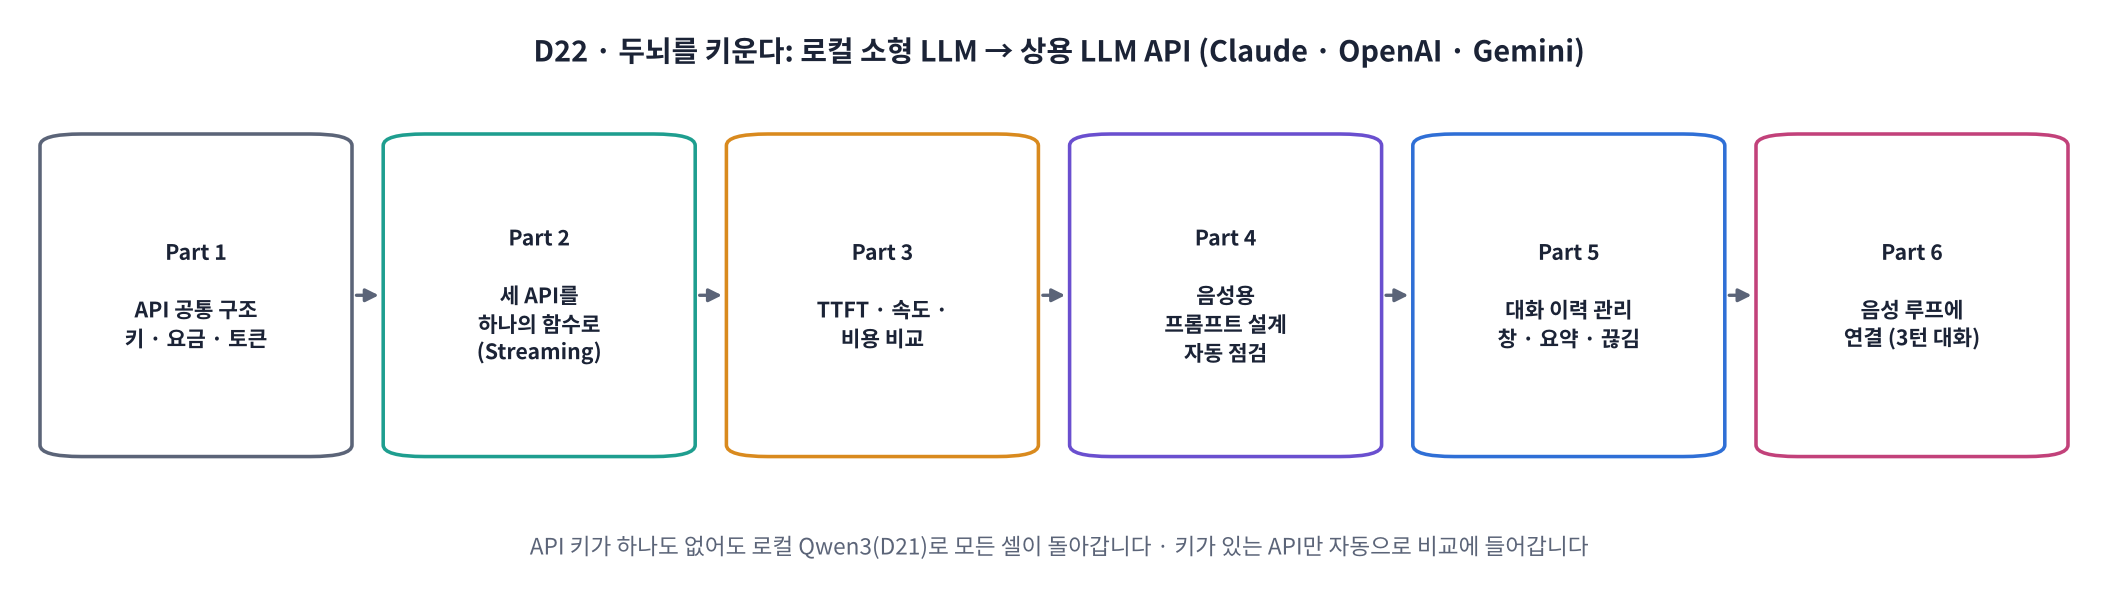

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | API 공통 구조 · 키 · 요금, 세 API를 하나의 함수로 | Part 0 ~ 2, 워크시트 1교시 | `ask()` 함수 |
| 2교시 | **TTFT · 속도 · 비용 비교**, 생각 모드의 영향 | Part 3, 워크시트 2교시 | API 비교표 |
| 3교시 | **음성용 프롬프트 설계 · 자동 점검**, 대화 이력(창 · 요약 · 끊김) | Part 4 ~ 5, 워크시트 3교시 | 프롬프트 통과율표 · 이력 전략 비교 |
| 4교시 | **음성 루프 연결** 3턴 대화, 정리 · 과제 | Part 6 ~ 7, 워크시트 4교시 | 3턴 대화 측정표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day22/animation.html) | 각 Part 설명을 볼 때 · 비용 계산기(D22-4) · 프롬프트 점검기(D22-5) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- ✏️ 표시가 있는 셀은 **직접 값을 바꿔** 실행하는 셀입니다(모델 이름, 프롬프트, 질문, 창 크기).

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 비서의 대답을 귀로 확인 |

> ⚙️ **런타임 → T4 GPU**. 로컬 부품(Silero VAD · Whisper · Qwen3 · MMS-TTS)은 D21과 같습니다.
>
> 🔑 **API 키 준비 (선택)**: Colab 왼쪽 **열쇠(보안 비밀)** 메뉴에 `ANTHROPIC_API_KEY` · `OPENAI_API_KEY` · `GEMINI_API_KEY` 중 **있는 것만** 넣고 '노트북 액세스'를 켭니다. **키가 하나도 없어도** 로컬 Qwen3로 모든 셀이 돌아가고, 키가 있는 API만 자동으로 비교에 들어갑니다. **키를 코드 · 노션 · 깃허브에 붙여 넣지 마세요.**
>
> 💸 오늘 API 사용량은 작은 모델 기준 **수십 원 수준**입니다(Part 3 비용표로 직접 확인). 무료 등급은 분당 요청 수 제한이 있어 가끔 429 오류가 날 수 있습니다.

> 🎬 **애니메이션 D22-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#flow) — Part 1~7 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **두뇌를 키우고(API), 기억을 붙인다(이력).**
>
> 🗣️ "어제 비서는 구조와 시간은 괜찮았지만 대답이 엉망이었죠. 1.7B 모델의 한계입니다. 오늘은 같은 구조에서 두뇌만 상용 API로 바꿉니다. 그리고 비서가 두 번째 질문에서 첫 질문을 기억하게 만듭니다."
>
> 🖥️ [D22-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#flow). **보안 원칙**을 먼저 공지.

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D18 ~ D21과 같은 방식)**: Colab에 깔린 torch · transformers · httpx · pydantic 버전을 그대로 고정하고, 세 API의 공식 Python SDK(`anthropic` · `openai` · `google-genai`)와 D21의 `silero-vad` · `uroman` · `jiwer`를 추가합니다.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 4분
>
> 🖥️ 설치 → import. 버전 줄에 `anthropic · openai · google-genai`가 보이면 OK. `httpx`도 고정 목록에 넣은 이유: SDK 설치가 Colab 기본 httpx를 바꾸지 않게.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "protobuf", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt -U anthropic openai google-genai
!pip install -q -c colab_constraints.txt silero-vad uroman jiwer
!apt-get -qq -y install ffmpeg > /dev/null
print("✅ 설치 완료")

In [ ]:
import os, re, io, json, time, copy, random, base64, subprocess, warnings, logging, inspect
from contextlib import contextmanager
from threading import Thread
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
for name in ["transformers", "httpx", "google_genai"]:
    logging.getLogger(name).setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
CHUNK = 512
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "anthropic", "openai", "google-genai", "silero-vad"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 ⚠️ T4로 바꾸세요")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(y, rate=sr))

def silence(sec):
    return np.zeros(int(sec * SR), np.float32)

def sync():
    if GPU: torch.cuda.synchronize()

# D16 정규화 (숫자 → 읽는 말)
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def read_number(s):
    s = s.replace(",", "")
    if "." in s:
        a, b = s.split(".", 1); return sino(int(a)) + "점" + "".join(DIGITS[int(c)] for c in b)
    return sino(int(s))
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d[\d,]*(?:\.\d+)?)\s*%", lambda m: read_number(m.group(1)) + " 퍼센트", t)
    t = re.sub(r"\d[\d,]*(?:\.\d+)?", lambda m: read_number(m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

## Part 1. LLM API의 공통 구조 · 키 · 요금

> 💬 **쉽게 말하면**: 세 회사의 API는 이름만 조금 다를 뿐 **같은 다섯 가지**를 받습니다. **모델 이름 · 시스템 지시 · 대화 목록(역할이 붙은 메시지) · 답 길이 상한 · Streaming 여부**. 답이 오면 **입력 · 출력 토큰 수**가 함께 와서 요금을 계산할 수 있습니다.

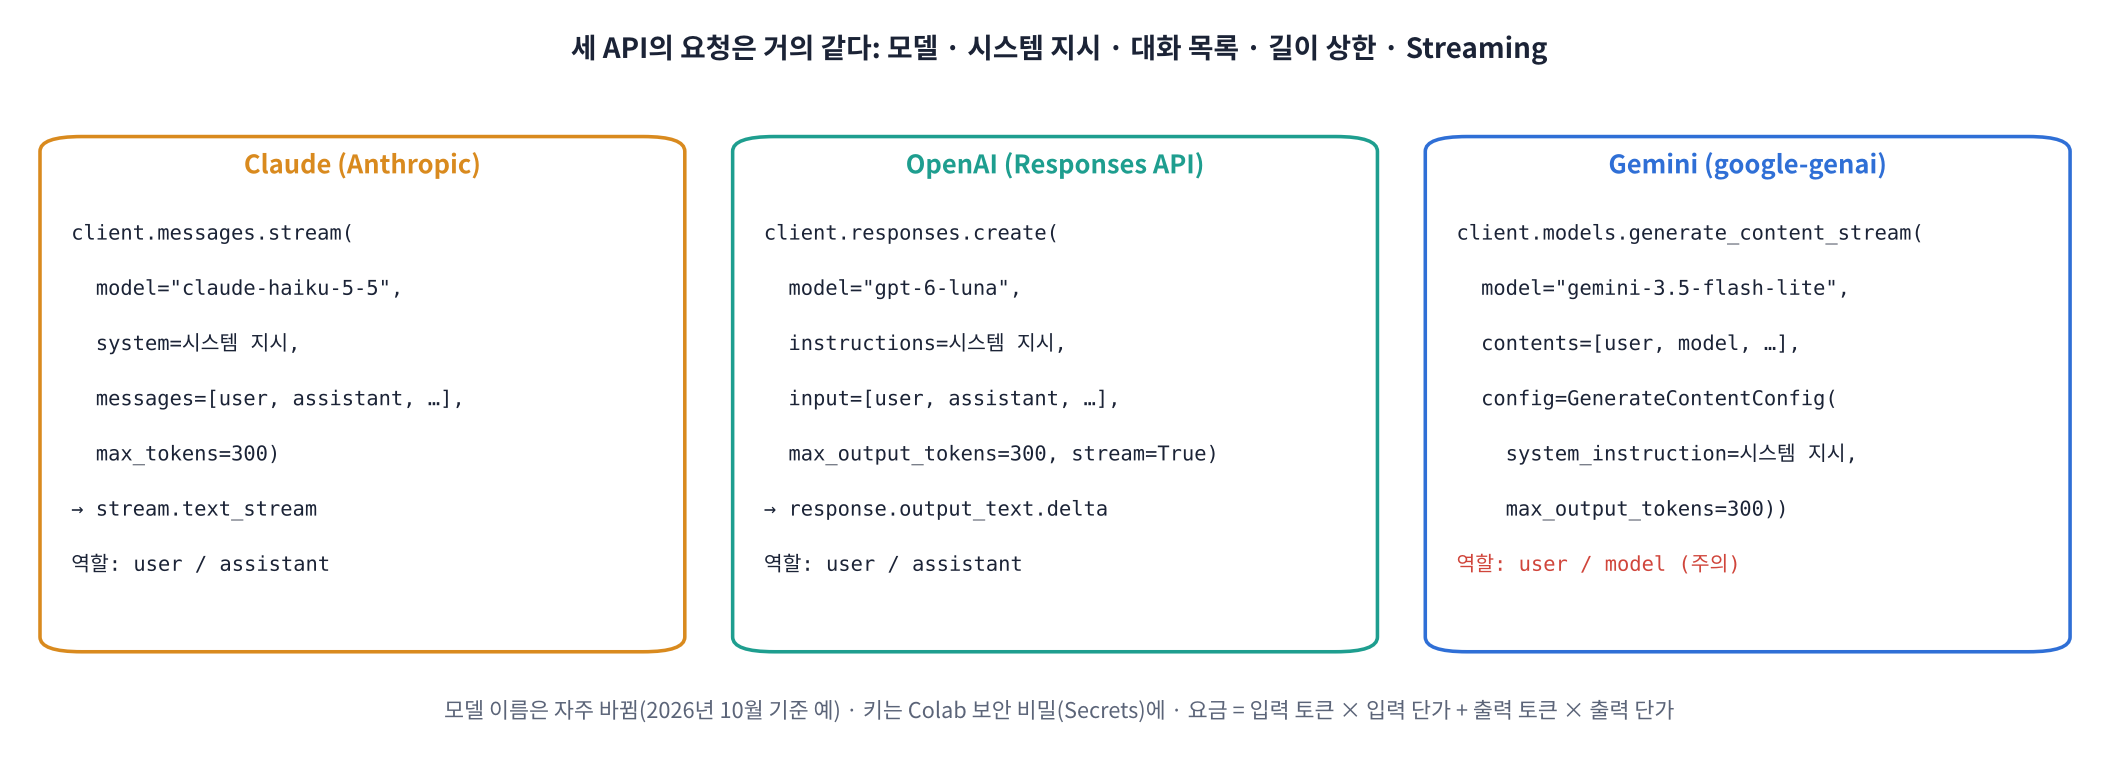

| 항목 | Claude (Anthropic) | OpenAI (Responses API) | Gemini (google-genai) |
|---|---|---|---|
| 오늘의 작은 · 빠른 모델 (2026년 10월 예) | `claude-haiku-5-5` | `gpt-6-luna` | `gemini-3.5-flash-lite` |
| 시스템 지시 | `system=` | `instructions=` | `config.system_instruction` |
| 대화 목록 | `messages=` (user / assistant) | `input=` (user / assistant) | `contents=` (user / **model**) |
| 길이 상한 | `max_tokens` (필수) | `max_output_tokens` | `config.max_output_tokens` |
| Streaming | `messages.stream()` → `text_stream` | `stream=True` → `response.output_text.delta` 이벤트 | `generate_content_stream()` → `chunk.text` |
| 키 이름 (Colab 보안 비밀) | `ANTHROPIC_API_KEY` | `OPENAI_API_KEY` | `GEMINI_API_KEY` |

> ⚠️ **2026년의 변화**: 최신 모델일수록 `temperature` · `top_p` 같은 샘플링 값을 **받지 않거나 무시**합니다(Claude 최신 API 버전은 넣으면 오류, Gemini 3.6+는 무시). 오늘 코드는 이 값들을 넣지 않습니다. 대신 **답의 길이 · 말투는 프롬프트와 `max_tokens`로** 조절합니다. 모델 이름과 요금은 자주 바뀌므로 **수업 당일 각 회사 문서**에서 확인하세요.

> 📐 **핵심 식 하나: 요금 = 입력 토큰 × 입력 단가 + 출력 토큰 × 출력 단가** (단가는 보통 '100만 토큰당 달러') — 음성 비서는 매 턴 **시스템 지시 + 이력 전체**를 다시 보내므로 입력 토큰이 턴마다 커집니다(Part 5).

> 🍎 **비유: 세 나라의 택배 회사.** 보내는 물건(대화)과 주소(모델)는 같은데, 송장 칸 이름(system / instructions / system_instruction)이 조금씩 다릅니다. **송장 변환기 하나(`ask()`)** 를 만들어 두면 어느 회사로든 보낼 수 있습니다.

> 🎬 **애니메이션 D22-2:** [세 API의 요청 · 응답 비교](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#anatomy) — API를 바꿔 요청 모양과 Streaming 이벤트 흐름 보기

**❓ 생각해 보기**: API 키가 노트북 코드에 그대로 적힌 채 깃허브에 올라가면 어떤 일이 생기나요? 이미 올렸다면?

<details>
<summary>답 보기</summary>

자동 스캐너가 몇 분 안에 찾아 **남의 요금으로 대량 호출**을 하거나 키를 팔 수 있습니다. 이미 올렸다면 **커밋을 지우는 것만으로는 부족**합니다(기록이 남음). 바로 해당 회사 콘솔에서 **키를 폐기(revoke)하고 새로 발급**, 사용량 · 결제 알림을 확인하세요. 예방: Colab 보안 비밀 · 환경 변수 · `.env`(+ `.gitignore`) · 사용 한도(budget) 설정 · 키마다 프로젝트 분리.

</details>

> ## 🎤 강사 스크립트 · Part 1 API 구조 · 키 · 요금  ⏱️ 10분
>
> 🎯 **세 API는 같은 다섯 가지를 받는다. 이름만 다르다.**
>
> 🖥️ [D22-2 세 API 비교](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#anatomy): 탭을 바꿔 요청 모양과 Streaming 이벤트를 비교.
>
> ⚠️ "최신 모델은 temperature를 받지 않거나 무시합니다. 예전 블로그 코드를 그대로 쓰면 오류가 납니다." 모델 이름 · 가격은 **오늘 기준 예**라고 꼭 말하기.
>
> ❓ 생각해 보기(키 유출) → 커밋 삭제로 부족 → **즉시 폐기 · 재발급**, 사용 한도.

In [ ]:
# 🔑 키 읽기: Colab 보안 비밀 → 없으면 환경 변수 → 없으면 None (키 값은 절대 출력하지 않음)
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"claude": "claude-haiku-5-5",                 # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
          "openai": "gpt-6-luna",
          "gemini": "gemini-3.5-flash-lite",
          "local": "Qwen/Qwen3-1.7B" if GPU else "Qwen/Qwen3-0.6B"}
PRICES = {"claude": dict(inp=0.10, out=0.50),            # ✏️ 100만 토큰당 USD (2026년 10월 공개 자료 기준 참고값 · 반드시 공식 가격표 확인)
          "openai": dict(inp=0.10, out=0.50),
          "gemini": dict(inp=0.54, out=4.50),
          "local": dict(inp=0.0, out=0.0)}

CLIENTS = {}
if secret("ANTHROPIC_API_KEY"):
    import anthropic
    CLIENTS["claude"] = anthropic.Anthropic(api_key=secret("ANTHROPIC_API_KEY"))
if secret("OPENAI_API_KEY"):
    import openai
    CLIENTS["openai"] = openai.OpenAI(api_key=secret("OPENAI_API_KEY"))
if secret("GEMINI_API_KEY"):
    from google import genai
    CLIENTS["gemini"] = genai.Client(api_key=secret("GEMINI_API_KEY"))
from google.genai import types                           # 키가 없어도 설정 클래스는 씀

for p in ["claude", "openai", "gemini"]:
    print(f"{p:7s} {'✅ 키 있음' if p in CLIENTS else '— 키 없음 (건너뜀)'}  모델: {MODELS[p]}")
print("local   ✅ 항상 사용 (Qwen3, Part 2에서 불러옴)")

> ## 🎤 강사 스크립트 · 키 읽기 셀  ⏱️ 5분
>
> ✅ 예상 출력: 키가 있는 API만 `✅ 키 있음`, 나머지 `— 키 없음 (건너뜀)`, `local ✅ 항상 사용`.
>
> ⚠️ 학생 화면을 돌아다닐 때 **키 값이 화면에 출력되지 않았는지** 확인. `print(secret(...))`를 하지 않도록.

## Part 2. 세 API와 로컬 LLM을 하나의 함수로 (Streaming)

> 💬 **쉽게 말하면**: API마다 다른 Streaming 방식을 **'글 조각을 하나씩 내주는 함수(generator)'** 로 똑같이 맞춥니다. 그러면 TTFT 측정 · 문장 자르기 · TTS(D21)를 **어떤 API든 같은 코드**로 쓸 수 있습니다.

👣 **Streaming 응답이 오는 모양 (한 단계씩)**
1. 요청을 보내면 서버가 연결을 열어 둔 채 **이벤트**를 하나씩 보냄 (SSE: `event: … / data: {JSON}`)
2. 시작 이벤트(메시지 시작 · 사용 토큰 일부) → **글 조각 이벤트 여러 개** → 끝 이벤트(멈춘 이유 · 최종 토큰 수)
3. SDK가 이 이벤트들을 파이썬 객체로 바꿔 줌. 우리는 **글 조각만 골라 `yield`** 하고, 끝에 **토큰 수를 `meta`에 기록**

| API | 글 조각을 꺼내는 곳 | 토큰 수를 꺼내는 곳 |
|---|---|---|
| Claude | `stream.text_stream` (글 조각 반복자) | `stream.get_final_message().usage` |
| OpenAI | 이벤트 `type == "response.output_text.delta"` 의 `.delta` | `response.completed` 이벤트의 `.response.usage` |
| Gemini | 각 `chunk.text` | 마지막 `chunk.usage_metadata` |

> 🎬 **애니메이션 D22-3:** [Streaming 이벤트 흐름](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#stream) — 이벤트가 도착하는 모습과 TTFT · 초당 토큰 측정

> ## 🎤 강사 스크립트 · Part 2 Streaming 구조  ⏱️ 4분
>
> 🖥️ [D22-3 Streaming 이벤트 흐름](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#stream): 이벤트가 하나씩 도착 → 첫 글자 시각 = TTFT.
>
> 🗣️ "세 회사 모두 SSE라는 같은 방식으로 이벤트를 흘려보냅니다. SDK가 그걸 파이썬 객체로 바꿔 주고, 우리는 글 조각만 고르면 됩니다."

In [ ]:
# 로컬 LLM (D21과 같은 Qwen3) + 로컬 Streaming 함수
from transformers import AutoTokenizer, AutoModelForCausalLM, TextIteratorStreamer
tok = AutoTokenizer.from_pretrained(MODELS["local"])
llm = AutoModelForCausalLM.from_pretrained(MODELS["local"], dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

def stream_local(system, messages, max_tokens, meta):
    text = tok.apply_chat_template([{"role": "system", "content": system}, *messages], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    th = Thread(target=llm.generate, kwargs=dict(**enc, max_new_tokens=max_tokens, do_sample=False, repetition_penalty=1.1, streamer=streamer))
    th.start()
    out = []
    for piece in streamer:
        out.append(piece); yield piece
    th.join()
    meta.update(in_tok=enc["input_ids"].shape[1], out_tok=len(tok("".join(out))["input_ids"]))
print("로컬 LLM:", MODELS["local"])

> ## 🎤 강사 스크립트 · 로컬 LLM  ⏱️ 2분
>
> 🗣️ "키가 없어도 수업을 따라올 수 있게 어제의 Qwen3도 같은 모양의 함수로 만들어 둡니다. 비교 기준선 역할도 합니다."

### 🧩 빈칸 실습 1 · 2 · 3: 세 API의 Streaming 함수
- 빈칸 1: Claude SDK의 Streaming 객체에서 **글 조각만 차례로 내주는 속성** 이름 (`text_…`)
- 빈칸 2: OpenAI Responses API의 글 조각 이벤트 이름 `response.output_text.____` (조각 = 변화분)
- 빈칸 3: Gemini는 비서(모델)의 이전 답을 `assistant`가 아니라 **다른 역할 이름**으로 부릅니다

> 💡 키가 없는 API는 실제로 호출하지 않으므로, 아래 점검은 '코드에 올바른 이름이 들어갔는지'와 로컬 LLM 결과로 확인합니다.

> ## 🎤 강사 스크립트 · 빈칸 실습 1 · 2 · 3  ⏱️ 15분
>
> 🆘 빈칸 1: "글(text) 조각의 흐름(stream)" → `text_stream`
> 🆘 빈칸 2: "변화분 = 델타" → `delta`
> 🆘 빈칸 3: "Gemini에서 비서의 역할 이름" → `model`
>
> ✅ 예상 출력: API별 1줄(provider · text · ttft 0.3 ~ 0.8초 · total · in_tok · out_tok · cost 0.0000x), local 1줄, `✅`. Gemini 첫 호출에 '추가 옵션이 거부됨'이 나올 수 있음(정상).
>
> ❓ "ask() 하나로 감싸면 뭐가 좋나요?" → 비교 실험 · API 교체 · D21 코드 재사용 · 장애 시 다른 API로 넘기기(fallback).

In [ ]:
# 🧩 빈칸 실습 1 · 2 · 3
EXTRA = {"claude": {}, "openai": {},                    # ✏️ API별 추가 옵션 (거부되면 ask()가 자동으로 빼고 다시 시도)
         "gemini": {"thinking_config": types.ThinkingConfig(thinking_level="minimal")}}

def stream_claude(system, messages, max_tokens, meta):
    with CLIENTS["claude"].messages.stream(model=MODELS["claude"], system=system, messages=messages,
                                           max_tokens=max_tokens, **EXTRA["claude"]) as s:
        for text in s.____:                                                               # 빈칸 1
            yield text
        u = s.get_final_message().usage
    meta.update(in_tok=u.input_tokens, out_tok=u.output_tokens)

def stream_openai(system, messages, max_tokens, meta):
    events = CLIENTS["openai"].responses.create(model=MODELS["openai"], instructions=system, input=messages,
                                                max_output_tokens=max(max_tokens, 16), stream=True, **EXTRA["openai"])
    for ev in events:
        if ev.type == "response.output_text.____":                                         # 빈칸 2
            yield ev.delta
        elif ev.type == "response.completed" and ev.response.usage:
            meta.update(in_tok=ev.response.usage.input_tokens, out_tok=ev.response.usage.output_tokens)

def to_gemini_contents(messages):
    return [{"role": "____" if m["role"] == "assistant" else "user", "parts": [{"text": m["content"]}]} for m in messages]   # 빈칸 3

def stream_gemini(system, messages, max_tokens, meta):
    cfg = types.GenerateContentConfig(system_instruction=system, max_output_tokens=max_tokens, **EXTRA["gemini"])
    for ch in CLIENTS["gemini"].models.generate_content_stream(model=MODELS["gemini"], contents=to_gemini_contents(messages), config=cfg):
        if ch.text:
            yield ch.text
        um = ch.usage_metadata
        if um and um.candidates_token_count:
            meta.update(in_tok=um.prompt_token_count, out_tok=um.candidates_token_count)

STREAMERS = {"claude": stream_claude, "openai": stream_openai, "gemini": stream_gemini, "local": stream_local}
AVAILABLE = [p for p in ["claude", "openai", "gemini"] if p in CLIENTS] + ["local"]

def ask(provider, system, messages, max_tokens=300, on_piece=None):
    # 어떤 API든 같은 방법으로: 글 조각을 모으며 TTFT · 전체 시간 · 토큰 · 비용을 잰다
    for attempt in range(2):
        meta, parts, ttft = {"in_tok": None, "out_tok": None}, [], None
        t0 = time.perf_counter()
        try:
            for piece in STREAMERS[provider](system, messages, max_tokens, meta):
                if ttft is None and piece.strip():
                    ttft = time.perf_counter() - t0
                parts.append(piece)
                if on_piece: on_piece(piece)
            break
        except Exception as e:
            if attempt == 0 and EXTRA.get(provider):
                print(f"⚠️ {provider}: 추가 옵션이 거부됨 → 옵션 없이 다시 시도 ({type(e).__name__}: {str(e)[:80]})")
                EXTRA[provider] = {}
                continue
            raise
    total = time.perf_counter() - t0
    text = re.sub(r"<think>.*?</think>|</?think>", "", "".join(parts), flags=re.S).strip()
    pr = PRICES[provider]
    cost = ((meta["in_tok"] or 0) * pr["inp"] + (meta["out_tok"] or 0) * pr["out"]) / 1e6
    return dict(provider=provider, text=text, ttft=ttft, total=total, in_tok=meta["in_tok"], out_tok=meta["out_tok"], cost=cost)

SHORT = "너는 한국어 음성 비서야. 한두 문장의 짧은 구어체로 답해."
rows = []
for p in AVAILABLE:
    r = ask(p, SHORT, [{"role": "user", "content": "안녕? 한 문장으로 자기소개 해 줘."}], max_tokens=120)
    rows.append({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})
display(pd.DataFrame(rows))
src_ok = "text_stream" in inspect.getsource(stream_claude) and '"response.output_text.delta"' in inspect.getsource(stream_openai)
check(src_ok and to_gemini_contents([{"role": "assistant", "content": "네"}])[0]["role"] == "model" and all(x["text"] for x in rows),
      hint="빈칸 1 = text_stream, 빈칸 2 = delta, 빈칸 3 = model")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
for text in s.text_stream:
if ev.type == "response.output_text.delta":
return [{"role": "model" if m["role"] == "assistant" else "user", ...}]
```

**해설**: **Claude**: `messages.stream()`은 `with` 블록 안에서 연결을 열어 두고, `text_stream`이 글 조각만 골라 줍니다(다른 이벤트 · 도구 호출 등은 걸러짐). 끝나면 `get_final_message()`로 전체 메시지와 `usage`(입력 · 출력 토큰)를 얻습니다. **OpenAI Responses API**: `stream=True`면 이벤트 객체가 하나씩 오고, 그중 `response.output_text.delta`의 `.delta`가 새 글 조각입니다. 마지막 `response.completed`에 `usage`가 들어 있습니다. **Gemini**: 대화 목록의 역할이 `user` / `model`이고, 내용은 `parts` 목록에 넣습니다. 시스템 지시는 대화 목록이 아니라 `config.system_instruction`에 넣습니다. 세 함수 모두 '글 조각을 yield + 끝에 meta 기록'으로 모양을 맞췄기 때문에, 위의 `ask()`와 D21의 문장 자르기 · TTS를 그대로 붙일 수 있습니다. 추가 옵션(Gemini `thinking_level="minimal"` 등)은 모델마다 지원이 달라 거부되면 자동으로 빼고 다시 시도합니다.

</details>

**결과 읽기**
- `ttft`(첫 글자까지) · `total`(전체) · `in_tok` · `out_tok` · `cost`(달러) 열을 API끼리 비교해 보세요. 한 번 호출 비용은 대개 **0.0001달러 아래**입니다.
- 같은 질문에 **API마다 길이와 말투가 다릅니다**. Part 4에서 프롬프트로 맞춥니다.
- 로컬 Qwen3는 TTFT가 짧지만(네트워크 없음) 초당 토큰이 적고 답의 품질이 낮습니다.

**❓ 생각해 보기**: TTFT를 잴 때 첫 조각이 빈 문자열이나 공백일 수 있습니다. ask()가 `piece.strip()`을 확인하는 이유는?

<details>
<summary>답 보기</summary>

일부 API · SDK는 연결 직후 **빈 조각이나 줄바꿈만 있는 조각**을 먼저 보냅니다. 이것을 첫 토큰으로 치면 TTFT가 실제보다 짧게 잡혀 **소리를 낼 수 있는 첫 글자**까지의 시간과 달라집니다. 음성 비서에게 의미 있는 것은 'TTS에 넘길 수 있는 첫 글자'이므로 공백이 아닌 조각부터 잽니다.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html)** — API 공통 구조, 역할 이름(user · assistant · model), 키 관리, 요금 식, 세 SDK의 Streaming 방식
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 1교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html). 자주 틀리는 문항: **Gemini 역할 이름(model)**, **시스템 지시를 넣는 곳**, **키 유출 대응**.

## Part 3. TTFT · 속도 · 비용 비교

> 💬 **쉽게 말하면**: 같은 질문을 같은 조건(같은 시스템 지시 · 같은 길이 상한)으로 여러 번 보내 **첫 글자까지(TTFT) · 초당 토큰 · 한 턴 비용**을 비교합니다. 음성 비서에게 가장 중요한 것은 **TTFT의 중앙값과 들쭉날쭉한 정도**입니다(D21 Latency Budget).

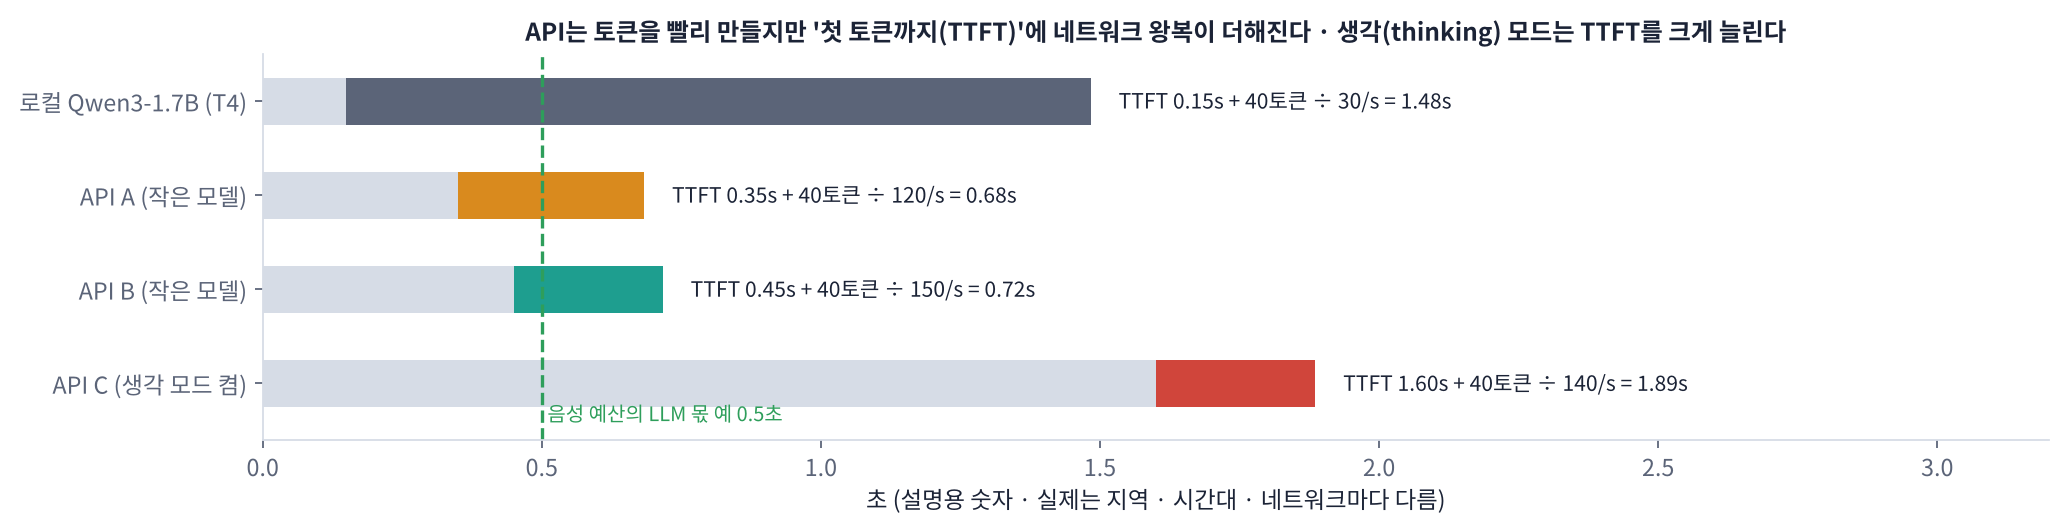

👣 **API의 TTFT를 이루는 것**
1. 네트워크 왕복 (한국 → 해외 서버: 수십 ~ 수백 ms)
2. 서버 대기열 (붐비는 시간대에 늘어남)
3. 입력 처리 (시스템 지시 + 이력이 길수록 늘어남 · 캐시로 줄일 수 있음)
4. **생각(thinking · reasoning) 단계** — 켜져 있으면 답하기 전에 수백 토큰을 먼저 생성 → TTFT가 수 초로 늘 수 있음

> 📐 **핵심 식 하나: 한 턴 비용 = (입력 토큰 × 입력 단가 + 출력 토큰 × 출력 단가) ÷ 1,000,000** — 하루 1만 턴 × 30일이면 한 턴 비용 × 30만.

> 🎬 **애니메이션 D22-4:** [음성 비서 비용 계산기](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#cost) — 하루 대화 수 · 이력 길이 · 단가를 바꿔 월 비용 보기
> 🎬 **애니메이션 D22-8:** [생각 모드와 TTFT](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#thinking) — 생각 토큰 수를 바꿔 첫 소리까지 시간 보기

> ## 🎤 강사 스크립트 · Part 3 비교 개념  ⏱️ 6분
>
> 🎯 **같은 조건 · 여러 번 · 중앙값과 최댓값.**
>
> 🖥️ [D22-4 비용 계산기](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#cost): 하루 1만 턴 · 이력 2,000토큰 → 월 비용. 이력을 줄이면 비용이 얼마나 주는지.
> 🖥️ [D22-8 생각 모드와 TTFT](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#thinking).

### 🧩 빈칸 실습 4 · 5: 비용 계산과 중앙값
- 빈칸 4: 단가 사전 `pr`에서 **출력 단가**의 키 이름 (`inp`의 짝)
- 빈칸 5: 몇 번의 측정에서 튀는 값의 영향을 덜 받는 대표값, pandas 메서드 이름 (D21 p50)

> ## 🎤 강사 스크립트 · 빈칸 실습 4 · 5  ⏱️ 15분
>
> 🆘 빈칸 4: "입력 단가 키가 inp라면 출력 단가는?" → `out` (따옴표 안)
> 🆘 빈칸 5: "D21의 p50을 pandas로" → `median`
>
> ✅ 예상 출력: `SUM` 표(API별 ttft 중앙값 0.3 ~ 0.8초, tok_per_s 50 ~ 200, local은 ttft 짧고 tok_per_s 20 ~ 40), `1000턴_USD` 0.0x ~ 0.x달러, 점 그래프, `✅`.
>
> ❓ 생각해 보기(TTFT 1.5초 이상) → 생각 모드 · 첫 연결 · 무료 대기열 · 긴 입력 · 먼 서버.
>
> ⚠️ 결과를 'A사가 B사보다 빠르다'로 일반화하지 않도록. **오늘 · 이 지역 · 이 모델** 결과.

In [ ]:
# 🧩 빈칸 실습 4 · 5
BENCH_QS = ["내일 서울 날씨는 어때?", "점심 메뉴 하나만 추천해 줘.", "회의를 3시 30분으로 옮겨 줄래?", "물 하루에 얼마나 마셔야 돼?"]
REPS = 2                                                 # ✏️ 반복 횟수 (무료 등급이면 1로)

def turn_cost(r, pr):
    return ((r["in_tok"] or 0) * pr["inp"] + (r["out_tok"] or 0) * pr["____"]) / 1e6                  # 빈칸 4

rows = []
for p in AVAILABLE:
    for rep in range(REPS):
        for q in BENCH_QS:
            r = ask(p, SHORT, [{"role": "user", "content": q}], max_tokens=150)
            gen = max(r["total"] - (r["ttft"] or 0), 1e-6)
            rows.append(dict(provider=p, 질문=q[:10], ttft=r["ttft"], total=r["total"], out_tok=r["out_tok"],
                             tok_per_s=(r["out_tok"] or 0) / gen, cost=turn_cost(r, PRICES[p]), 글자=len(r["text"])))
BENCH = pd.DataFrame(rows)
SUM = BENCH.groupby("provider")[["ttft", "total", "tok_per_s", "out_tok", "글자", "cost"]].____().round(4)   # 빈칸 5
SUM["ttft_최대"] = BENCH.groupby("provider")["ttft"].max().round(3)
SUM["1000턴_USD"] = (BENCH.groupby("provider")["cost"].mean() * 1000).round(3)
display(SUM)

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, p in enumerate(SUM.index):
    v = BENCH[BENCH.provider == p]["ttft"]
    ax.plot(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(v)), "o", alpha=0.7)
    ax.plot([SUM.loc[p, "ttft"]] * 2, [i - 0.3, i + 0.3], "k-", lw=2)
ax.set_yticks(range(len(SUM))); ax.set_yticklabels(SUM.index); ax.axvline(0.5, color="green", ls="--")
ax.set_xlabel("TTFT (s) · black bar = median"); plt.tight_layout(); plt.show()
check(abs(turn_cost(dict(in_tok=1_000_000, out_tok=1_000_000), dict(inp=1.0, out=3.0)) - 4.0) < 1e-9
      and abs(SUM.loc["local", "ttft"] - BENCH[BENCH.provider == "local"]["ttft"].median()) < 1e-3,
      hint="빈칸 4 = out, 빈칸 5 = median")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return ((r["in_tok"] or 0) * pr["inp"] + (r["out_tok"] or 0) * pr["out"]) / 1e6
SUM = BENCH.groupby("provider")[[...]].median().round(4)
```

**해설**: 단가는 '100만 토큰당 달러'이므로 토큰 수 × 단가를 100만으로 나눕니다. 대부분의 API는 **출력 단가가 입력의 4 ~ 10배**입니다. 그래서 음성 비서처럼 **답이 짧은** 서비스는 출력 비용이 작고, 대신 매 턴 이력을 다시 보내는 **입력 비용**이 커집니다(Part 5). 대표값을 평균 대신 **중앙값(median = p50)** 으로 잡는 이유는 네트워크 때문에 가끔 튀는 TTFT가 평균을 끌어올리기 때문입니다. `ttft_최대` 열과 함께 보세요(D21 p95). 측정 횟수가 적으므로 순위는 '오늘 이 시간, 이 지역'의 결과일 뿐입니다.

</details>

**결과 읽기**
- **TTFT 중앙값이 0.5초 안쪽**인 API가 음성 비서에 유리합니다. 같은 API라도 시간대 · 지역에 따라 달라지므로 **수업 시간에 잰 숫자를 표로 남겨** 두세요.
- `tok_per_s`는 API가 로컬 T4보다 몇 배 빠른 경우가 많습니다. 답이 길수록 이 차이가 커집니다.
- `1000턴_USD`: 작은 모델이면 1,000턴에 수십 센트 수준입니다. **이력이 길어지면 입력 토큰이 늘어** 금방 몇 배가 됩니다.

**❓ 생각해 보기**: TTFT가 1.5초 넘게 나온 API가 있다면, 가능한 원인과 확인 방법은?

<details>
<summary>답 보기</summary>

① **생각(thinking · reasoning) 모드**가 켜져 있음 → 출력 토큰 수가 글자 수에 비해 지나치게 많으면 의심(보이지 않는 생각 토큰도 출력으로 계산되는 경우가 많음). 생각 정도를 낮추는 옵션(Gemini `thinking_level`, OpenAI `reasoning` effort 등, 모델마다 다름)을 확인. ② 처음 호출(연결 · TLS 준비) → 두 번째부터 비교. ③ 무료 등급 대기열 · 붐비는 시간대. ④ 시스템 지시 · 이력이 김. ⑤ 먼 지역의 서버. 원인별로 하나씩 바꿔 다시 재는 것이 디버깅의 기본입니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html)** — TTFT의 구성, 생각 모드, 초당 토큰, 요금 계산, 중앙값과 최댓값, 비교 실험의 조건
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 2교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html). 자주 틀리는 문항: **출력 단가가 더 비쌈**, **중앙값을 쓰는 이유**, **생각 토큰도 출력 요금**.

## Part 4. 음성 대화용 프롬프트 설계와 자동 점검

> 💬 **쉽게 말하면**: 음성 비서의 답은 **화면이 아니라 귀로** 듣습니다. 목록 · 표 · 굵은 글씨 · 이모지는 소리로 낼 수 없고, 긴 답은 늦고 지루합니다. 좋은 음성 프롬프트를 **감으로 고르지 않고**, 답을 자동 점검해 **통과율로 비교**합니다.

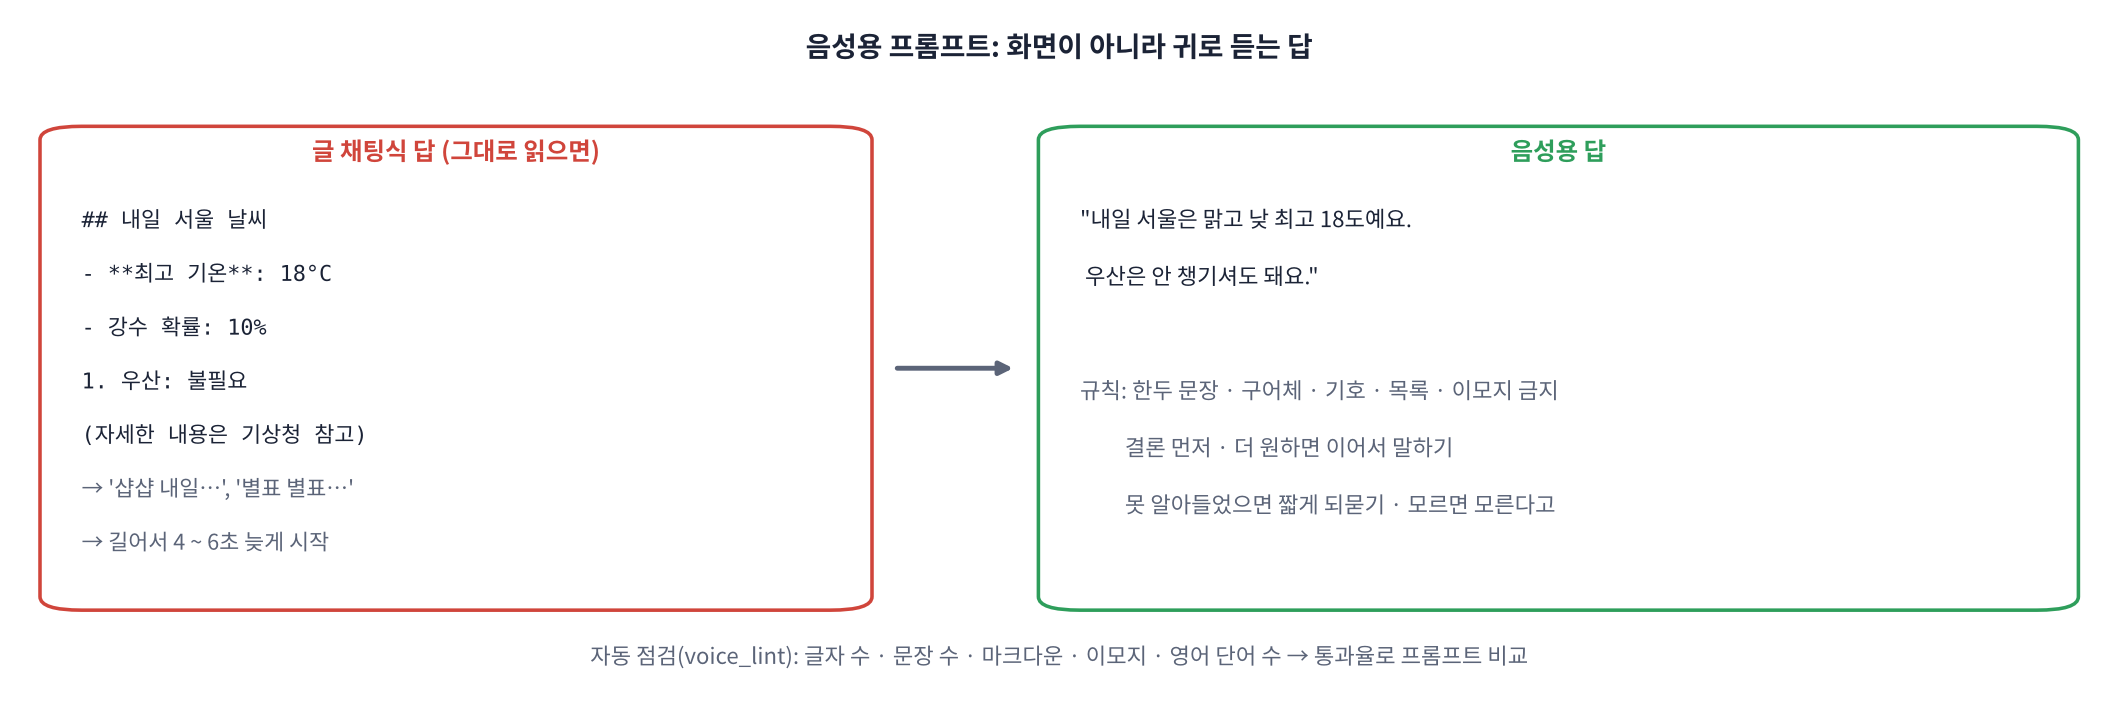

| 규칙 | 이유 | 프롬프트 문장 예 |
|---|---|---|
| 한두 문장 · 60 ~ 80자 | 지연 · 듣기 피로 | "한두 문장, 80자 안쪽으로 답해" |
| 결론 먼저 | 첫 문장만 들어도 쓸모 | "가장 중요한 답을 첫 문장에" |
| 기호 · 목록 · 이모지 금지 | 읽을 수 없음 | "목록, 표, 마크다운, 이모지를 쓰지 마" |
| 구어체 · 존댓말 일관 | 듣기 자연스러움 | "'~해요'체로 말해" |
| 더 원하면 이어서 | 긴 내용은 나눠서 | "길어지면 요점만 말하고 더 들을지 물어봐" |
| 못 알아들었으면 되묻기 | STT 오류 대비 | "질문이 이상하면 짧게 되물어" |
| 모르면 모른다고 · 실시간 정보 주의 | 지어내기 방지 | "날씨 · 환율처럼 실시간 정보는 모른다고 말해" |
| 영어 · 기호를 소리 나는 대로 | TTS 발음 | "영어 단어는 한글로 소리 나는 대로" |

> 🎬 **애니메이션 D22-5:** [음성용 답 점검기](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#lint) — 답 문장을 고쳐 쓰며 점검 항목이 바뀌는 것 보기

> ## 🎤 강사 스크립트 · Part 4 음성 프롬프트  ⏱️ 6분
>
> 🎯 **귀로 듣는 답: 짧게 · 결론 먼저 · 기호 금지 · 되묻기 · 모르면 모른다고.**
>
> 🖥️ [D22-5 음성용 답 점검기](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#lint): 글 채팅식 답을 붙여 넣고 하나씩 고치며 ✅로 바꾸기.
>
> 🍎 라디오 원고 비유.

### 🧩 빈칸 실습 6: 음성용 답 자동 점검 `voice_lint()`
글자 수 · 문장 수 · 마크다운 · 이모지 · 영어 단어 수를 세고, 기준을 모두 지키면 `ok=True`입니다. 빈칸에는 **문장 수의 상한을 담은 함수 인자 이름**을 넣으세요.

> ## 🎤 강사 스크립트 · 빈칸 실습 6  ⏱️ 8분
>
> 🆘 "함수 인자 중 문장 수 상한" → `max_sent` (`MAX_SENT`를 쓰면 인자가 무시됨)
>
> ✅ 예상 출력: 표 3줄 — 1번 ok True, 2번 마크다운 · 이모지로 False, 3번 문장 5개로 False, `✅`.

In [ ]:
# 🧩 빈칸 실습 6
MAX_CHARS, MAX_SENT = 80, 2
MD = re.compile(r"(^\s*([-*•]|\d+[.)])\s)|[*#`|]|\[[^\]]*\]\(", re.M)
EMOJI = re.compile(r"[\U0001F300-\U0001FAFF☀-➿]")

def voice_lint(text, max_chars=MAX_CHARS, max_sent=MAX_SENT):
    r = dict(글자=len(text),
             문장=len([s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]),
             마크다운=bool(MD.search(text)), 이모지=bool(EMOJI.search(text)),
             영어=len(re.findall(r"[A-Za-z]{3,}", text)))
    r["ok"] = r["글자"] <= max_chars and r["문장"] <= ____ and not r["마크다운"] and not r["이모지"]       # 빈칸 6
    return r

samples = ["내일 서울은 맑고 낮 최고 18도예요. 우산은 필요 없어요.",
           "## 내일 날씨\n- **최고 기온**: 18도\n- 강수 확률: 10% ☀️",
           "네. 알겠어요. 바로 옮길게요. 3시 30분으로 바꿨어요. 더 필요한 것 있나요?"]
display(pd.DataFrame([dict(답=s.replace("\n", " ⏎ ")[:40], **voice_lint(s)) for s in samples]))
check([voice_lint(s)["ok"] for s in samples] == [True, False, False] and voice_lint("가. 나. 다.", max_sent=3)["ok"],
      hint="빈칸 6 = max_sent")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
r["ok"] = r["글자"] <= max_chars and r["문장"] <= max_sent and not r["마크다운"] and not r["이모지"]
```

**해설**: 함수 인자 `max_sent`를 써야 호출할 때 기준을 바꿀 수 있습니다(`MAX_SENT`를 직접 쓰면 `max_sent=3`으로 불러도 2로 고정). 두 번째 답은 마크다운 · 이모지 · 줄바꿈 때문에, 세 번째 답은 **문장이 5개**라 실패합니다. 점검기는 완벽하지 않습니다(예: '18°C'의 기호, 너무 딱딱한 말투는 못 잡음). 그래도 **수십 개 질문에 자동으로 돌려 통과율**을 내면 프롬프트를 바꿀 때마다 좋아졌는지 나빠졌는지 숫자로 알 수 있습니다(D20의 품질 게이트와 같은 생각).

</details>

In [ ]:
# ✏️ 프롬프트 세 개 × 까다로운 질문 6개 → 통과율 비교
PROMPTS = {
    "기본": "너는 친절한 AI 비서야.",
    "음성 v1 (D21)": ("너는 한국어 음성 비서야. 네 대답은 소리로 읽힌다. 한두 문장, 60자 안쪽의 짧은 구어체로 답해. "
                      "목록, 표, 마크다운, 이모지, 괄호는 쓰지 마. 모르는 것은 모른다고 짧게 말해."),
    "음성 v2": ("너는 '하나'라는 이름의 한국어 음성 비서야. 네 말은 스피커로 읽히고 사용자는 화면을 보지 않아.\n"
                "규칙:\n1) 가장 중요한 답을 첫 문장에, 전체는 한두 문장 80자 안쪽, '~해요'체.\n"
                "2) 목록, 표, 마크다운, 이모지, 괄호, 특수 기호를 쓰지 마. 영어 단어는 한글로 소리 나는 대로 써.\n"
                "3) 내용이 길면 요점만 말하고 '더 자세히 알려 드릴까요?'라고 물어.\n"
                "4) 질문이 끊기거나 이상하면 추측하지 말고 짧게 되물어.\n"
                "5) 날씨, 환율, 뉴스처럼 실시간 정보는 지금 확인할 수 없다고 말해.\n"
                "예) 사용자: 파이썬 설치 어떻게 해? → 비서: 파이썬 공식 홈페이지에서 설치 파일을 받아 실행하면 돼요. 단계별로 알려 드릴까요?"),
}
LINT_QS = ["파이썬 설치 방법 알려 줘.", "내일 서울 날씨 어때?", "오늘 원 달러 환율 얼마야?",
           "내 일 서 울 날 씬 어 때",                    # STT가 잘못 띄어 쓴 경우
           "회의를 3시 30분으로 옮겨 줄래?", "요즘 기분이 좀 우울해."]
LINT_PROVIDERS = AVAILABLE[:1] + (["local"] if AVAILABLE[0] != "local" else [])   # 첫 API + 로컬 (비용 · 시간 절약)
rows = []
for p in LINT_PROVIDERS:
    for pname, system in PROMPTS.items():
        for q in LINT_QS:
            r = ask(p, system, [{"role": "user", "content": q}], max_tokens=200)
            rows.append(dict(provider=p, 프롬프트=pname, 질문=q[:12], 답=r["text"][:60].replace("\n", " ⏎ "), ttft=r["ttft"], **voice_lint(r["text"])))
LINT = pd.DataFrame(rows)
PASS = LINT.pivot_table(index="프롬프트", columns="provider", values="ok", aggfunc="mean").reindex(list(PROMPTS)).round(2)
display(PASS)
display(LINT[LINT.provider == LINT_PROVIDERS[0]][["프롬프트", "질문", "답", "글자", "문장", "마크다운", "ok"]])

> ## 🎤 강사 스크립트 · 프롬프트 통과율 실험  ⏱️ 10분
>
> ✅ 예상 출력(API): 통과율 기본 0.0 ~ 0.3 → 음성 v1 0.5 ~ 0.8 → 음성 v2 0.7 ~ 1.0. local은 낮게 나옴(작은 모델).
>
> 🗣️ "'내 일 서 울 날 씬 어 때'에 v2가 되묻나요? 환율을 지어내지 않나요?" — `답` 열을 함께 읽기.
>
> ⚠️ '우울해' 질문: 민감한 대화의 원칙(짧고 따뜻하게, 필요하면 도움받을 곳 안내)을 짚기.

**결과 읽기**
- 큰 API 모델은 대개 **기본 → 음성 v1 → 음성 v2** 순으로 통과율이 오릅니다. 작은 로컬 모델은 규칙을 잘 따르지 못합니다(그래서 `speakable()` 같은 **후처리 안전망**이 필요).
- **'내 일 서 울 날 씬 어 때'** 에 v2가 되묻는지, **환율**에 지어내지 않고 '확인할 수 없다'고 하는지 `답` 열에서 확인하세요. 이것은 점검기가 못 잡는 **내용 품질**입니다.
- **'우울해'** 같은 말에는 짧지만 따뜻하게, 필요하면 도움을 받을 곳을 안내하는 것이 좋습니다. 민감한 상황의 응답 원칙은 서비스마다 정해 두어야 합니다.

**❓ 생각해 보기**: v2 프롬프트가 길어서 매 턴 입력 토큰이 늘어납니다. 지연과 비용을 줄이려면?

<details>
<summary>답 보기</summary>

① 시스템 지시는 매 턴 **같은 앞부분**이므로 **프롬프트 캐싱**(API마다 이름 · 방법이 다름 · 캐시된 입력은 단가가 몇 분의 일)을 켜면 비용과 TTFT가 줄어듭니다. ② 예시(few-shot)는 꼭 필요한 것만. ③ 규칙을 짧은 문장으로. ④ 그래도 길면 '규칙은 짧게, 후처리(speakable · voice_lint 게이트)로 보완'. 프롬프트도 D20의 생성기처럼 **점검 → 고침 → 다시 점검**의 반복입니다.

</details>

> ## 🎤 강사 스크립트 · 결과 읽기  ⏱️ 3분
>
> ❓ 생각해 보기(긴 프롬프트의 비용) → 프롬프트 캐싱 · 예시 최소화 · 후처리 안전망.

## Part 5. 대화 이력 관리: 창 · 요약 · 끊김

> 💬 **쉽게 말하면**: LLM API는 **기억이 없습니다**. 두 번째 질문에서 첫 질문을 기억하는 것처럼 보이는 것은, 우리가 **매번 이전 대화 전체를 다시 보내기** 때문입니다. 대화가 길어지면 입력 토큰(= 비용 · TTFT)이 계속 늘어나므로, **최근 N턴만 보내고(창) 오래된 내용은 한 줄로 요약**합니다.

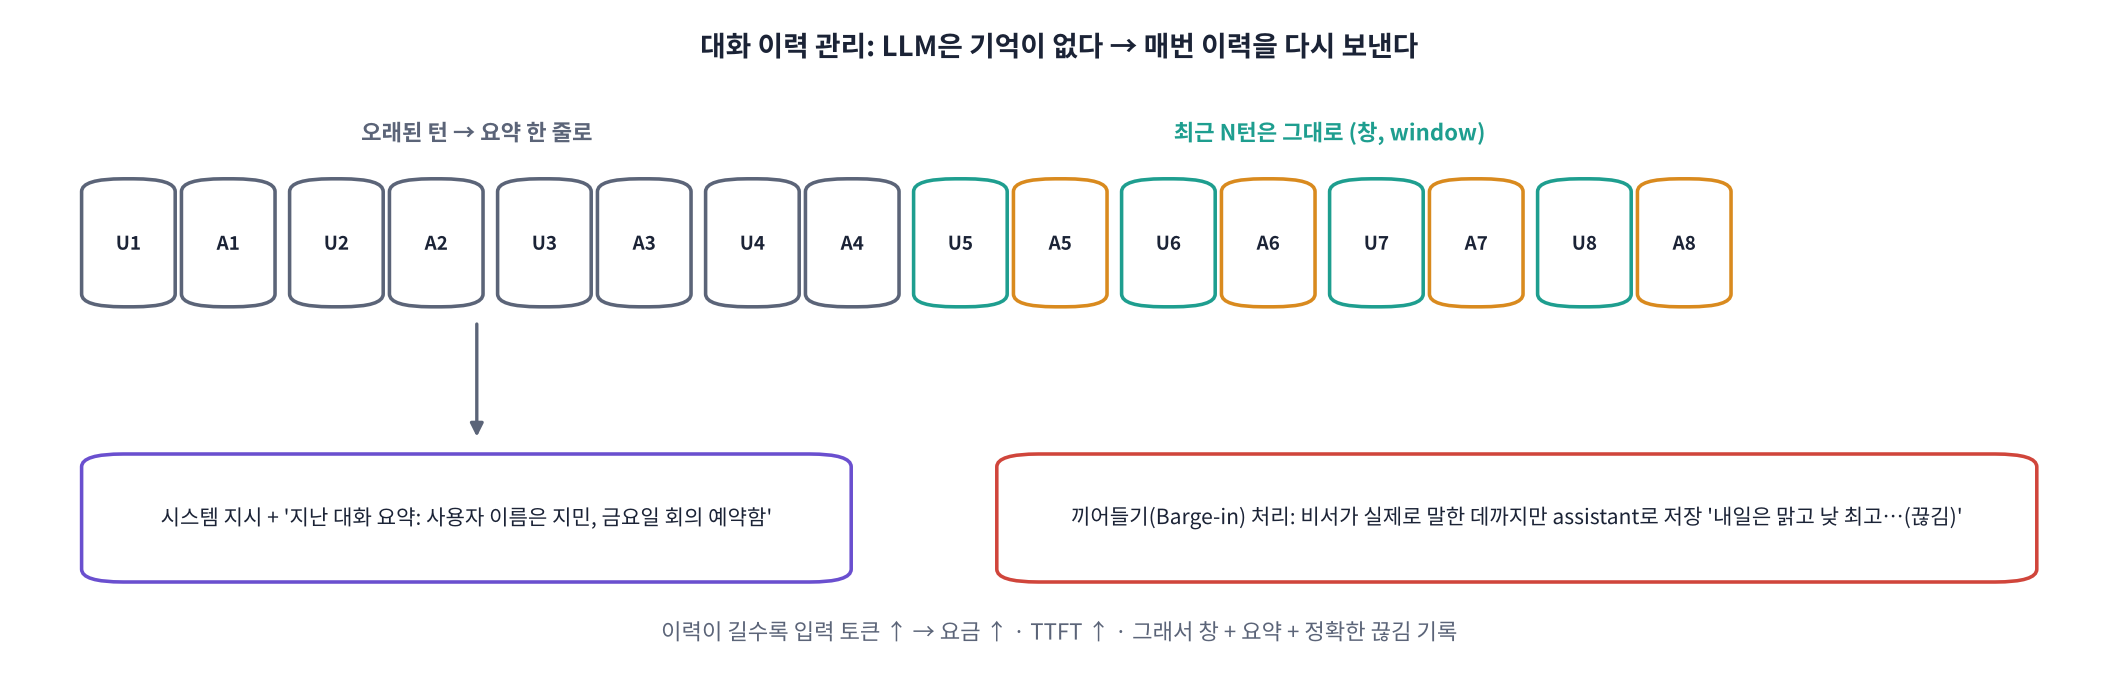

👣 **한 턴의 이력 처리 (한 단계씩)**
1. 보낼 메시지 = 시스템 지시(+ 지난 대화 요약) + **최근 N턴(user · assistant 쌍)** + 이번 사용자 말
2. 답을 받아 말함
3. **실제로 말한 데까지만** assistant 메시지로 저장(사용자가 끼어들면 뒷부분은 듣지 못했으므로)
4. 이력이 창보다 길어지면 창 밖으로 나가는 턴을 **요약**에 합침

> 🍎 **비유: 회의록.** 매 회의에 지난 1년치 녹취를 다 틀지 않고, **최근 회의 몇 번의 기록 + 그 전의 요약 한 장**을 가져옵니다. 그리고 회의록에는 **실제로 말한 것만** 적습니다.

> 📐 **핵심 식 하나: 보낼 메시지 수 = 최근 N턴 × 2(user + assistant) + 1(이번 말)** — 쌍으로 잘라야 순서(user → assistant → user …)가 깨지지 않습니다.

> 🎬 **애니메이션 D22-6:** [이력 창 · 요약 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#history) — 턴이 쌓일 때 전략별 입력 토큰과 기억 보기
> 🎬 **애니메이션 D22-7:** [끼어들기와 이력 저장](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#bargein) — 끼어든 시점에 따라 이력에 남는 말 보기

> ## 🎤 강사 스크립트 · Part 5 대화 이력  ⏱️ 6분
>
> 🎯 **LLM은 기억이 없다. 우리가 매번 다시 보낸다.**
>
> 🖥️ [D22-6 이력 창 · 요약 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#history): 턴을 늘리며 전략별 입력 토큰 · 기억 여부.
> 🖥️ [D22-7 끼어들기와 이력 저장](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#bargein).
>
> 🗣️ "ChatGPT가 기억하는 것처럼 보이는 것도 앱이 이력을 다시 보내는 것입니다."

### 🧩 빈칸 실습 7 · 8: 대화 이력 클래스
- 빈칸 7: 최근 `max_turns`턴을 고를 때 한 턴이 메시지 **몇 개**인지 (user + assistant)
- 빈칸 8: 끼어들기가 있었다면 답 전체가 아니라 **실제로 말한 글자 수**까지만 저장합니다. 그 글자 수를 담은 인자 이름

> ## 🎤 강사 스크립트 · 빈칸 실습 7 · 8  ⏱️ 12분
>
> 🆘 빈칸 7: "한 턴 = user 1개 + assistant 1개" → `2`
> 🆘 빈칸 8: "실제로 말한 글자 수를 담은 인자" → `spoken`
>
> ✅ 예상 출력: `['질문3', '답3', '질문4', '답4', '다음 질문']`, `끊긴 답 저장: 내일은 맑고 낮 최 …(사용자가 끼어듦)`, `✅`.
>
> ❓ "홀수로 자르면?" → assistant로 시작 → Claude는 오류.

In [ ]:
# 🧩 빈칸 실습 7 · 8
class Conversation:
    def __init__(self, system, max_turns=4, summarize_with=None):
        self.system, self.max_turns, self.summarize_with = system, max_turns, summarize_with
        self.turns, self.summary = [], ""                 # turns: user · assistant 메시지가 번갈아 쌓인 목록

    def messages(self, user_text):
        recent = self.turns[-self.max_turns * ____:] if self.max_turns else list(self.turns)               # 빈칸 7
        system = self.system + (f"\n\n[지난 대화 요약] {self.summary}" if self.summary else "")
        return system, recent + [{"role": "user", "content": user_text}]

    def commit(self, user_text, reply, spoken=None):
        said = reply if spoken is None else reply[:____].rstrip() + " …(사용자가 끼어듦)"                  # 빈칸 8
        self.turns += [{"role": "user", "content": user_text}, {"role": "assistant", "content": said}]
        if self.max_turns and self.summarize_with and len(self.turns) > self.max_turns * 2:
            old, self.turns = self.turns[:2], self.turns[2:]          # 창 밖으로 나가는 가장 오래된 한 턴
            self.summary = summarize(self.summarize_with, self.summary, old)

SUMMARY_SYSTEM = "너는 대화 기록을 요약하는 도우미야. 이름, 날짜, 시간, 약속, 선호처럼 나중에 필요한 사실만 한국어 한두 문장으로 적어."
def summarize(provider, prev, old_turns):
    log = "\n".join(f"{'사용자' if m['role'] == 'user' else '비서'}: {m['content']}" for m in old_turns)
    r = ask(provider, SUMMARY_SYSTEM, [{"role": "user", "content": f"기존 요약: {prev or '없음'}\n새 대화:\n{log}\n\n합친 요약:"}], max_tokens=120)
    return r["text"]

c = Conversation("테스트", max_turns=2)
for i in range(5):
    c.commit(f"질문{i}", f"답{i}")
sys_t, msgs = c.messages("다음 질문")
c.commit("내일 날씨?", "내일은 맑고 낮 최고 18도예요. 우산은 필요 없어요.", spoken=10)
print([m["content"] for m in msgs]); print("끊긴 답 저장:", c.turns[-1]["content"])
check(len(msgs) == 5 and msgs[0]["role"] == "user" and msgs[0]["content"] == "질문3" and c.turns[-1]["content"].startswith("내일은 맑고 낮 최"),
      hint="빈칸 7 = 2, 빈칸 8 = spoken")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
recent = self.turns[-self.max_turns * 2:]
said = reply if spoken is None else reply[:spoken].rstrip() + " …(사용자가 끼어듦)"
```

**해설**: 한 턴 = user 메시지 1 + assistant 메시지 1이므로 최근 N턴은 **끝에서 2N개**입니다. 홀수로 자르면 목록이 assistant로 시작해 일부 API(특히 Claude)는 **'첫 메시지는 user여야 한다'는 오류**를 냅니다. 끼어들기 때는 TTS가 실제로 재생한 글자 수(`spoken`)까지만 저장하고 표시를 붙입니다. 그래야 다음 턴에 LLM이 '아까 말씀드렸듯이 우산은…'처럼 **사용자가 듣지 못한 말을 들었다고 착각**하지 않습니다(D28 Barge-in에서 재생 위치를 실제로 잽니다). 요약은 창 밖으로 나가는 턴만 모아 기존 요약과 합칩니다.

</details>

In [ ]:
# ✏️ 세 가지 이력 전략으로 6턴 대화 → 입력 토큰 증가와 '기억' 비교
P_HIST = AVAILABLE[0]                                   # 키가 있는 첫 API (없으면 local)
VOICE = PROMPTS["음성 v2"]
SCRIPT = ["안녕, 내 이름은 지민이야.", "나 금요일 오후 2시에 치과 예약이 있어.", "점심 메뉴 하나만 추천해 줘.",
          "그럼 저녁은 뭐가 좋을까?", "주말에 갈 만한 산책 장소 있을까?", "내 이름이 뭐였지? 그리고 치과는 언제라고 했지?"]
STRATS = {"전체 이력": dict(max_turns=0), "최근 2턴": dict(max_turns=2), "최근 2턴 + 요약": dict(max_turns=2, summarize_with=P_HIST)}
rows, finals = [], {}
for name, kw in STRATS.items():
    conv = Conversation(VOICE, **kw)
    for t, user in enumerate(SCRIPT, 1):
        system, msgs = conv.messages(user)
        r = ask(P_HIST, system, msgs, max_tokens=150)
        conv.commit(user, r["text"])
        rows.append(dict(전략=name, 턴=t, 보낸_메시지=len(msgs), 입력_토큰=r["in_tok"], ttft=r["ttft"], cost=r["cost"]))
    finals[name] = (r["text"], conv.summary)
HIST = pd.DataFrame(rows)
display(HIST.pivot(index="턴", columns="전략", values="입력_토큰"))
for name, (ans, summ) in finals.items():
    print(f"[{name}] 마지막 답: {ans[:80]}" + (f"\n   요약: {summ[:100]}" if summ else ""))
ax = HIST.pivot(index="턴", columns="전략", values="입력_토큰").plot(marker="o", figsize=(7, 3))
ax.set_ylabel("input tokens per turn"); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · 이력 전략 실험  ⏱️ 10분
>
> ✅ 예상 출력: 입력 토큰 표 — 전체 이력은 턴마다 증가, 최근 2턴은 일정, 요약은 거의 일정. 마지막 답: 전체 이력 · 요약은 '지민 · 금요일 2시'를 기억, 최근 2턴만은 기억 못함.
>
> ❓ 생각해 보기(이력 속 개인정보) → 보관 기간 · 마스킹 · 고지 · API 데이터 정책 · 접근 권한.

**결과 읽기**
- **전체 이력**은 턴마다 입력 토큰이 계단처럼 늘어납니다. 30턴, 100턴이 되면 비용과 TTFT가 눈에 띄게 커집니다.
- **최근 2턴**은 입력이 일정하지만 마지막 질문(이름 · 치과)을 **잊어버립니다**.
- **최근 2턴 + 요약**은 입력을 거의 일정하게 유지하면서 이름 · 약속을 기억합니다(요약 호출 비용이 조금 더 듦).
- 요약이 틀리면 그 틀린 사실이 계속 따라다닙니다. 중요한 정보(예약 시간)는 요약 대신 **구조화된 메모(이름: 지민, 예약: 금 14:00)** 로 따로 저장하는 방법이 더 안전합니다(D23 Tool Calling · D24 MCP).

**❓ 생각해 보기**: 음성 비서 대화 이력에는 개인정보(이름 · 건강 · 일정)가 쌓입니다. 이력을 다룰 때 지켜야 할 것은?

<details>
<summary>답 보기</summary>

① **꼭 필요한 기간만 보관**하고 대화가 끝나면 삭제(또는 요약만 남기기) ② API로 보낼 때 **불필요한 개인정보는 가리기**(전화번호 · 카드 번호 마스킹) ③ 이용자에게 **녹음 · 기록 사실 고지와 동의**(D19 · D34) ④ API 회사의 **데이터 보관 · 학습 사용 정책** 확인(기업용 계정은 대개 학습에 쓰지 않음) ⑤ 로그 접근 권한 제한. 기술보다 **설계 단계의 원칙**이 중요합니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html)** — 음성용 프롬프트 규칙, voice_lint, 되묻기 · 모른다고 하기, LLM은 기억이 없다, 창 · 요약, 끼어들기 저장
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 3교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html). 자주 틀리는 문항: **turns[-N*2:]의 이유**, **끼어들기 저장**, **요약의 위험(틀린 요약이 따라다님)**.

## Part 6. 음성 루프에 연결: 3턴 대화

> 💬 **쉽게 말하면**: D21의 Cascade v2(VAD → Whisper → **LLM** → 문장마다 TTS)에서 LLM 자리에 오늘 만든 `ask()`를, 대화 목록 자리에 `Conversation`을 끼웁니다. 이제 **이어지는 대화**를 하는 음성 비서입니다.

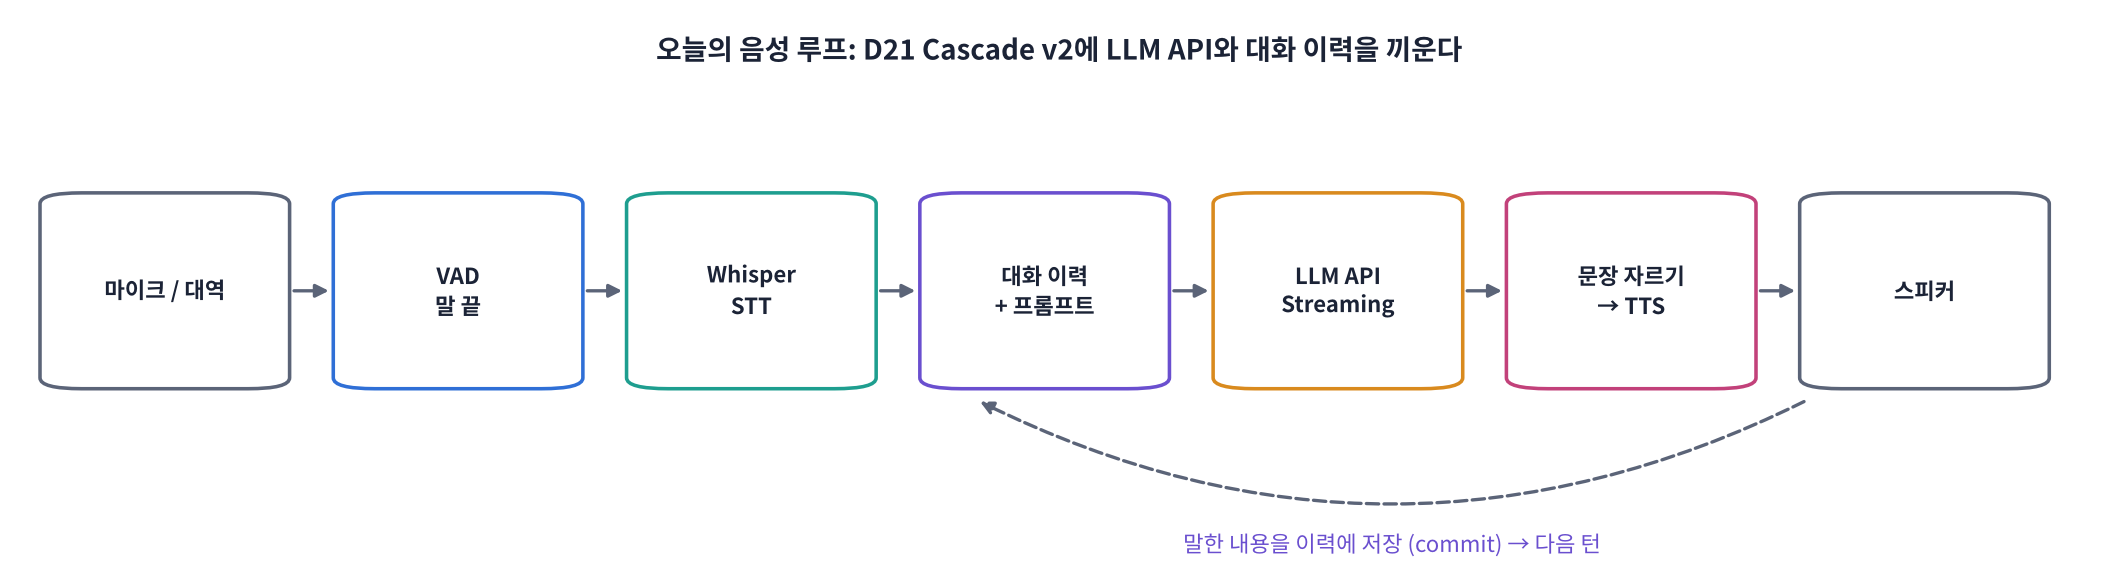

> 🎬 **애니메이션 D22-9:** [API 키 안전 점검](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#keys) — 상황별로 키가 안전한지 판단해 보기

> ## 🎤 강사 스크립트 · Part 6 음성 루프  ⏱️ 4분
>
> 🖥️ [D22-9 API 키 안전 점검](https://imguru-mooc.github.io/AI_Voice/day22/animation.html#keys): 상황 카드 5개를 반 전체가 판단.
>
> 🗣️ "D21의 루프에서 LLM과 대화 목록만 바꿉니다. 부품을 바꿔 끼울 수 있는 것, 이것이 Cascade의 장점입니다."

In [ ]:
# D21의 음성 부품 (VAD · Whisper · MMS TTS) + 문장 자르기
from silero_vad import load_silero_vad, VADIterator
from transformers import WhisperProcessor, WhisperForConditionalGeneration, VitsModel
import uroman as ur
vad = load_silero_vad()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()

def stt(y):
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def speakable(text):
    text = re.sub(r"<think>.*?</think>|</?think>", "", text, flags=re.S)
    text = re.sub(r"[*#`>\[\]()_~|]|[\U0001F300-\U0001FAFF☀-➿]", "", text)
    return normalize_ko(text).strip() or "죄송해요, 다시 말씀해 주세요."

def tts(text, seed=0):
    set_seed(seed)
    enc = tts_tok(U.romanize_string(speakable(text)), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        y = to_np(tts_model(**enc).waveform[0])
    sync(); return y

def endpoint(y, min_silence_ms=500):
    it = VADIterator(vad, sampling_rate=SR, min_silence_duration_ms=min_silence_ms); ends = []
    for i in range(0, len(y) - CHUNK + 1, CHUNK):
        ev = it(torch.from_numpy(np.ascontiguousarray(y[i:i + CHUNK])))
        if ev and "end" in ev: ends.append(dict(detected=(i + CHUNK) / SR, speech_end=ev["end"] / SR))
    it.reset_states(); return ends

END = re.compile(r"[.!?。…~]+\s")
def sentences(pieces, min_chars=8):
    buf = ""
    for p in pieces:
        buf += p
        while (m := END.search(buf, min_chars)):
            yield buf[:m.end()].strip(); buf = buf[m.end():]
    if buf.strip(): yield buf.strip()

def user_voice(text, seed=0):                            # 대역 사용자 목소리 (D21과 같음)
    y = librosa.effects.pitch_shift(tts(text, seed=seed + 50), sr=SR, n_steps=-3)
    return np.concatenate([silence(0.8), y, silence(1.5)]).astype(np.float32)
print("음성 부품 준비 완료 · STT:", ASR_NAME)

> ## 🎤 강사 스크립트 · 음성 부품  ⏱️ 3분
>
> ✅ 예상 출력: `음성 부품 준비 완료 · STT: openai/whisper-small`. D21과 같은 코드라 설명은 짧게.

### 🧩 빈칸 실습 9: 한 턴 = 듣기 → 이력 → API Streaming → 문장 TTS → 이력 저장
`voice_turn()`은 D21 v2와 같지만, LLM 자리에 `ask()`의 Streaming(글 조각 콜백)을, 대화 목록 자리에 `Conversation`을 씁니다. 말을 마친 뒤 **이번 턴을 이력에 저장**하는 메서드 이름을 넣으세요.

> 💡 오늘은 간단하게, LLM 답을 끝까지 받은 뒤 문장으로 나눠 TTS 합니다. 그래도 **첫 문장이 완성된 시각**을 따로 재서 'Streaming이었다면 첫 소리가 언제였을지'를 계산합니다(진짜 동시 처리는 D27 Pipecat).

> ## 🎤 강사 스크립트 · 빈칸 실습 9 · 3턴 대화  ⏱️ 15분
>
> 🆘 "이번 턴을 이력에 저장하는 메서드, 빈칸 7 · 8의 클래스" → `commit`
>
> ✅ 예상 출력: 🎧 사용자 · 비서 3쌍, 표 3줄(v2v_stream 0.9 ~ 1.5초, 입력 토큰이 턴마다 증가), 세 번째 답에 '오후 3시', `✅`.
>
> 🎧 세 번째 턴을 스피커로. "기억했나요?"
>
> ⚠️ STT가 '오후 3시'를 잘못 들었다면 답도 틀립니다 → '들은_말' 열로 원인 찾기.

In [ ]:
# 🧩 빈칸 실습 9
def voice_turn(conv, provider, y, min_silence_ms=500):
    T = {}
    ends = endpoint(y, min_silence_ms)
    end = ends[0] if ends else dict(detected=len(y) / SR, speech_end=len(y) / SR)
    T["endpoint"] = end["detected"] - end["speech_end"]
    t = time.perf_counter(); heard = stt(y[: int(end["detected"] * SR)]); T["stt"] = time.perf_counter() - t
    system, msgs = conv.messages(heard)
    t_llm, buf, first = time.perf_counter(), [""], [None]
    def on_piece(p):                                     # 글 조각이 올 때마다: 첫 문장이 완성된 시각 기록
        buf[0] += p
        if first[0] is None and END.search(buf[0], 8):
            first[0] = time.perf_counter() - t_llm
    r = ask(provider, system, msgs, max_tokens=200, on_piece=on_piece)
    sents = list(sentences(iter([r["text"]])))
    t = time.perf_counter(); audio1 = tts(sents[0]); T["tts_first"] = time.perf_counter() - t
    audio = np.concatenate([audio1] + [tts(s) for s in sents[1:]]) if len(sents) > 1 else audio1
    T["ttft"] = r["ttft"]; T["first_sentence"] = first[0] if first[0] is not None else r["total"]
    T["v2v_stream"] = T["endpoint"] + T["stt"] + T["first_sentence"] + T["tts_first"]   # Streaming이었다면
    T["v2v_v1"] = T["endpoint"] + T["stt"] + r["total"] + T["tts_first"]                # 다 받고 말했다면
    conv.____(heard, r["text"])                                                        # 빈칸 9
    return dict(heard=heard, reply=r["text"], audio=audio, cost=r["cost"], in_tok=r["in_tok"], T=T)

P_VOICE = AVAILABLE[0]                                   # ✏️ Part 3에서 TTFT가 가장 짧았던 API로 바꿔 보세요
DIALOG = ["안녕, 나는 지민이야.", "내일 오후 3시에 팀 회의가 있어. 기억해 줘.", "내 회의 몇 시라고 했지?"]
conv = Conversation(PROMPTS["음성 v2"], max_turns=4, summarize_with=P_VOICE)
rows = []
for i, q in enumerate(DIALOG):
    y = user_voice(q, i)
    play(y, SR, f"🙂 사용자: {q}")
    r = voice_turn(conv, P_VOICE, y)
    play(r["audio"], SR, f"🤖 {P_VOICE}: {r['reply'][:50]}")
    rows.append(dict(턴=i + 1, 들은_말=r["heard"][:20], 대답=r["reply"][:40], 입력_토큰=r["in_tok"], cost=r["cost"],
                     **{k: round(v, 3) for k, v in r["T"].items() if v is not None}))
TURNS = pd.DataFrame(rows)
display(TURNS)
print(f"이력 메시지 {len(conv.turns)}개 · 3턴 비용 합계 ${TURNS.cost.sum():.5f}")
check(len(conv.turns) == 6 and conv.turns[-1]["role"] == "assistant" and conv.turns[-1]["content"] == r["reply"],
      hint="빈칸 9 = commit")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
conv.commit(heard, r["text"])
```

**해설**: `commit()`이 이번 턴의 (들은 말, 대답)을 이력에 쌓아야 다음 턴의 `messages()`가 그것을 함께 보냅니다. 빠뜨리면 비서는 매 턴 **처음 만난 사람처럼** 대답합니다(세 번째 질문 '회의 몇 시?'에 답하지 못함). 이력에는 **STT가 들은 말**이 들어간다는 점도 중요합니다. STT가 틀리면 틀린 말이 이력에 남습니다. `v2v_stream`과 `v2v_v1`의 차이가 D21에서 본 Streaming의 이득입니다. API는 초당 토큰이 많아서 이 차이가 로컬보다 작을 수 있습니다.

</details>

**결과 읽기**
- 세 번째 턴에서 비서가 **'오후 3시'** 를 기억해 말하면 이력 관리가 제대로 된 것입니다. `들은_말`이 틀렸다면 STT 문제입니다(Cascade의 장점: 어디서 틀렸는지 보임).
- `v2v_stream`이 **1초 안팎**이면 D21 목표에 가깝습니다. 남은 큰 덩어리는 대개 **말 끝 기다리기(0.5초)** 와 STT입니다 → 6주차(스트리밍 STT · Turn Detection · Pipecat).
- `입력_토큰`이 턴마다 늘어나는 것을 확인하세요(시스템 지시 + 이력).

**❓ 생각해 보기**: 세 번째 질문의 답을 이력이 아니라 '메모'에서 찾게 하려면 어떻게 할까요? (내일 D23 예고)

<details>
<summary>답 보기</summary>

LLM에게 **도구(함수)** 를 알려 주고(예: `save_note(key, value)`, `get_note(key)`), LLM이 '회의 시간을 저장해야겠다'고 판단하면 **도구 호출**을 하게 합니다. 우리 코드가 실제로 메모를 저장 · 조회하고 결과를 다시 LLM에 돌려줍니다. 이것이 **Tool Calling(Function Calling)** 이고, 사내 문서에서 찾아 답하게 하는 것이 **RAG**입니다. 이력 요약보다 정확하고, 예약 · 조회 같은 실제 작업을 할 수 있습니다.

</details>

> ## 🎤 강사 스크립트 · D23 예고  ⏱️ 3분
>
> ❓ 생각해 보기(메모 도구) → Tool Calling · RAG. "내일은 비서가 일을 합니다."

## Part 7. 정리 · 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| API 공통 구조 | 모델 · 시스템 지시 · 대화 목록 · 길이 상한 · Streaming | `ask(provider, system, messages)` |
| 키 관리 | 보안 비밀 · 환경 변수 · 출력 · 커밋 금지 · 유출 시 폐기 | `secret("ANTHROPIC_API_KEY")` |
| Claude Streaming | 글 조각 반복자 | `s.text_stream` |
| OpenAI Streaming | 이벤트 중 글 조각 | `response.output_text.delta` |
| Gemini 역할 | 비서 = model | `{"role": "model"}` |
| 비용 | 입력 × 단가 + 출력 × 단가 | `pr["out"]` |
| 비교 | 중앙값 + 최댓값 | `.median()` |
| 음성 프롬프트 | 짧게 · 결론 먼저 · 기호 금지 · 되묻기 · 모르면 모른다고 | `voice_lint(..., max_sent)` |
| 대화 이력 | 최근 N턴(쌍) + 요약 + 말한 데까지만 | `turns[-N * 2:]`, `reply[:spoken]`, `commit()` |

### 🔐 API를 쓸 때 체크리스트
- [ ] 키는 보안 비밀 · 환경 변수에만, 노트북 · 노션 · 깃허브에 붙이지 않기 · 사용 한도(budget) 설정
- [ ] 개인정보는 필요한 만큼만 보내고 가리기 · 보관 기간 정하기 · 녹음 · 기록 고지
- [ ] 모델 이름 · 가격 · 지원 옵션은 **수업 · 배포 당일 공식 문서**로 확인
- [ ] 오류(429 요청 제한 · 5xx · 시간 초과) 때 **짧게 사과하고 다시 시도**하는 말을 준비 ('잠시만요, 다시 확인해 볼게요')

### 📝 과제
1. **API 비교표**: 질문 10개 × 2회로 Part 3을 다시 돌려 API별 TTFT p50 · 최댓값 · 1,000턴 비용을 표로 정리하고, 내 서비스에 고를 API와 이유를 3줄로 쓰세요.
2. **프롬프트 개선**: 음성 v2를 고쳐 '음성 v3'를 만들고, 까다로운 질문 10개(직접 추가)로 통과율과 되묻기 · 모른다고 하기 성공 여부를 비교하세요.
3. **이력 전략 실험**: 10턴 대화 대본을 만들어 세 전략의 입력 토큰 합계와 마지막 '기억 질문' 정답 여부를 비교하세요.

### ✅ 개념 워크시트 제출
> 📝 **[D22 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html)** — 4교시 × 10문항. 4개 탭 채점 → 제출 → 📋 캡처 → 노션에 붙이고, **API 비교표 · 프롬프트 통과율표 · 이력 전략표 · 3턴 대화 측정표**도 함께 붙이세요. **API 키와 녹음 파일은 절대 붙이지 마세요.**

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day22/animation.html) — D22-1 ~ D22-9

### 다음 시간 (D23 · Tool Calling & RAG)
비서가 말만 하는 것이 아니라 **일을 하게** 만듭니다. Function Calling으로 **예약 · 조회 함수**를 LLM이 직접 부르게 하고, 사내 문서를 검색해 근거를 들어 답하는 **RAG**를 음성 비서에 붙입니다.

> ## 🎤 강사 스크립트 · Part 7 정리 · 과제  ⏱️ 7분
>
> 🎯 **오늘 한 줄: 세 API를 하나의 함수로 감싸 같은 조건에서 재고, 음성용 프롬프트는 자동 점검으로 고르고, 이력은 창 · 요약 · '말한 데까지만'으로 관리한다.**
>
> 🖥️ 🔐 체크리스트를 함께 읽기.
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day22/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션(**키 · 녹음 금지**).
>
> ➡️ "내일은 비서가 말만 하지 않고 일을 합니다. Function Calling으로 예약 · 조회, RAG로 사내 문서 답변."